#Analysis of the Bias-Variance Trade-off using K-Fold Cross Validation

The goal of this experiment is to study how the complexity of a polynomial regression model affects its generalization error, using 5-fold cross validation as the method for hyperparameter selection.

The analysis connects the theoretical concepts of bias, variance, underfitting and overfitting with a practical model selection procedure.
In order to understand more formally the concepts of overfitting and underfitting we can resort to the notions of Bias and Variance.



*   The Bias measures the distortion of an estimate
*   The Variance measures the dispersion of an estimate

The learning goal is to find the best trade-off between bias and variance
The method that I choose for model selection (and evaluation) is the K-fold cross-validation:

**K-fold CV procedure:**
1. The training set is partitioned in k disjoint sets Va1, ..., Vak and K different predictors h1, h2, ..., hk
are trained by iteratively applying the Hold-out approach on the k-pairs (Tri = Tr − Vai, Vai).
2. Final error is obtained by individually computing the errors of h1, ..., hk on the corresponding validation
set and averaging the results.
The above procedure is repeated for different values of the hyper-parameters and the predictor with the
smallest final error is selected.

The special case where k = |Tr| (the validation sets are made of only one example) is called leave-one-out
cross-validation.
* For higher values of k, we have larger training sets, hence less bias, but smaller validation sets, hence
more variance.
* For lower values of k, we have smaller training sets, hence more bias, but larger validation sets, hence
less variance.





In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

**Dataset and Target Function**

The true function is:

$f(x) = \sin(2\pi x)$

The data include Gaussian noise:

$y = f(x) + \varepsilon,\ \varepsilon \sim \mathcal{N}(0,\, 0.1^2)$

We generated:

* 80 points for the training set
* 200 points for the test set


In [27]:

# 1. Generate synthetic dataset

# For reproducibility
np.random.seed(42)

# True underlying function
def f(x):
    return np.sin(2 * np.pi * x)

# Number of samples
n_train = 80
n_test = 200

# Training data sampled uniformly in [0,1]
X_train = np.random.rand(n_train, 1)
y_train = f(X_train).ravel() + np.random.normal(0, 0.1, n_train)

# Test data (never used during training or CV)
X_test = np.random.rand(n_test, 1)
y_test = f(X_test).ravel() + np.random.normal(0, 0.1, n_test)

**Models Considered**

We analysed polynomial regression models with degrees:

$p \in \{1,3,5,9,15,30\}$

Increasing the degree increases model flexibility (lower bias) but also the risk of overfitting (higher variance).

**5-Fold Cross Validation Procedure**

The training set was divided into 5 disjoint folds.

For each polynomial degree:

1. five models are trained (one per fold)

2. the MSE is computed on each validation set

3. the average validation error is computed:
$$
\mathrm{CV}(p) = \frac{1}{5} \sum_{i=1}^{5} \mathrm{MSE}_i
$$



In [29]:

# 2. K-fold Cross Validation for model selection

degrees = [1, 3, 5, 9, 15,30]  # polynomial degrees to compare
k = 5  # number of folds
kf = KFold(n_splits=k, shuffle=True, random_state=42)

cv_errors = []  # store mean CV error for each degree

for p in degrees:
    fold_errors = []  # stores MSE for each fold

    # Transformer for polynomial features of degree p
    poly = PolynomialFeatures(p)

    # Perform K-fold CV
    for train_index, val_index in kf.split(X_train):
        X_tr, X_val = X_train[train_index], X_train[val_index]
        y_tr, y_val = y_train[train_index], y_train[val_index]

        # Transform data into polynomial space
        X_tr_p = poly.fit_transform(X_tr)
        X_val_p = poly.transform(X_val)

        # Train linear regression on the polynomial features
        model = LinearRegression()
        model.fit(X_tr_p, y_tr)

        # Predict on validation fold
        y_pred = model.predict(X_val_p)

        # Compute MSE for the fold
        fold_errors.append(mean_squared_error(y_val, y_pred))

    # Average CV error for degree p
    cv_errors.append(np.mean(fold_errors))

**Results**

Below are the cross-validation errors obtained for each polynomial degree.


**Best degree selected: p = 5**

These results clearly show the typical bias-variance trend:

The **degree-1 model** performs poorly because it is too simple to capture the sinusoidal shape : **high bias (underfitting)**.

As the **degree increases from 3 to 5**, the CV error decreases significantly, reaching a minimum at **degree 5**.

Increasing the degree beyond 5 produces only marginal improvement or even degradation:

* Degree 9 performs similarly but slightly worse than degree 5.

* Degree 15 begins to show increased CV error.

* Degree 30 performs very poorly due to **overfitting and numerical instability : high variance.**

In [35]:
# 3. Select best model (degree with lowest CV error)

best_degree = degrees[np.argmin(cv_errors)]

print("Cross-validation errors per degree:")
for d, err in zip(degrees, cv_errors):
    print(f"  degree {d}: {err}")

print("\nSelected degree:", best_degree)

Cross-validation errors per degree:
  degree 1: 0.21298352920580405
  degree 3: 0.015221824927435762
  degree 5: 0.010415458607136009
  degree 9: 0.010533948022800211
  degree 15: 0.018683662731230167
  degree 30: 0.311234951235579

Selected degree: 5


**Final Test Evaluation**

After choosing the optimal degree via cross validation, the model was retrained on the entire training set and evaluated on the test set.

In [36]:
# 4. Train final model on full training set

# Prepare polynomial features for best degree
poly_best = PolynomialFeatures(best_degree)

X_train_p = poly_best.fit_transform(X_train)
X_test_p = poly_best.transform(X_test)

# Train the final model
model_best = LinearRegression()
model_best.fit(X_train_p, y_train)

# Predict on the test set
y_pred_test = model_best.predict(X_test_p)
test_mse = mean_squared_error(y_test, y_pred_test)

print("Final test MSE:", test_mse)

Final test MSE: 0.009649060292859672


The test MSE is close to the CV MSE, indicating good generalization performance.

**Role of Cross Validation**

The 5-fold cross validation procedure effectively identifies the optimal polynomial degree:

* Reduces the likelihood of selecting overfitted models

* Provides a more stable and reliable estimate of generalization error compared to a single hold-out validation set

The CV error plot visualizes this U-shaped trend, confirming the theoretical expectations.

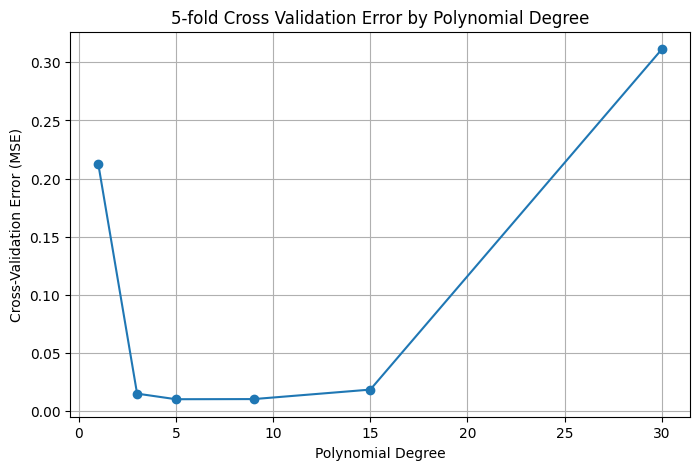

In [40]:
# 5. Plot CV error for each degree

plt.figure(figsize=(8,5))
plt.plot(degrees, cv_errors, marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("Cross-Validation Error (MSE)")
plt.title("5-fold Cross Validation Error by Polynomial Degree")
plt.grid(True)
plt.show()

**Visualization of the Learned Model**

The plot of the **true function vs the learned polynomial model** highlights:

* How well the selected degree-5 polynomial approximates the underlying sinusoidal function

* That the model captures the main pattern while ignoring most of the noise in the training data

* The training points show the noise distribution, illustrating the challenge of fitting noisy data

This visual comparison complements the quantitative CV error analysis and provides a clear demonstration of the model’s generalization capability.

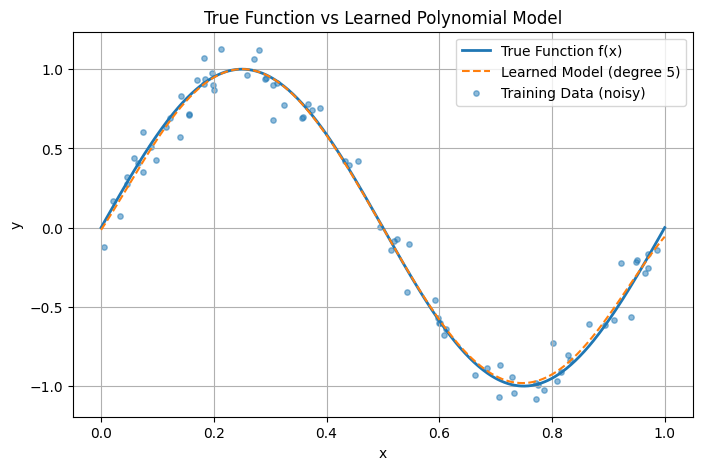

In [41]:
# 6. Plot true function vs learned model

# Create dense grid for plotting
X_plot = np.linspace(0, 1, 500).reshape(-1, 1)

# Predict using the learned model
X_plot_p = poly_best.transform(X_plot)
y_plot_pred = model_best.predict(X_plot_p)

# True function (no noise)
y_true = f(X_plot)

plt.figure(figsize=(8,5))
plt.plot(X_plot, y_true, label="True Function f(x)", linewidth=2)
plt.plot(X_plot, y_plot_pred, label=f"Learned Model (degree {best_degree})", linestyle="--")
plt.scatter(X_train, y_train, s=15, alpha=0.5, label="Training Data (noisy)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("True Function vs Learned Polynomial Model")
plt.legend()
plt.grid(True)
plt.show()

**Effect of k in K-Fold**

From theory:

Small k (e.g., k = 2) : higher bias, lower variance

Large k (e.g., k = 10) : lower bias, higher variance

Leave-one-out (k = n_train) : minimal bias, maximal variance, and high computational cost

Thus, the choice of k balances the stability of the error estimate and the computational efficiency.

**Conclusions**

The experiment demonstrates that **K-fold cross validation** is an effective and practical method for hyperparameter selection:

* It helps to **avoid both underfitting and overfitting**

* It identifies the **polynomial degree that best balances bias and variance**

* The selected model (degree 5) shows **strong generalization performance on unseen test data**

The analysis combines theoretical understanding (bias-variance decomposition) with practical implementation (CV and polynomial regression), providing a clear framework for model selection in noisy datasets.